# 01 · Exploring the data

**Goal:** understand the data before modelling it: how often each result happens, how stable that is over time, and how good the bookmakers' probabilities are (the benchmark to aim for).

Data: [football-data.co.uk](https://www.football-data.co.uk). Run `python -m footy.ingest` first to build `data/football.db`.

After running each section, write your findings in the **Notes** cells: in your own words, 1–2 sentences each. This is what you'll say in an interview.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from footy.data import OUTCOMES, implied_probabilities, load_matches
from footy.plotting import GRID, OUTCOME_COLORS, OUTCOME_LABELS, SINGLE, TEXT_MUTED, use_style

use_style()
df = load_matches()
df = df.join(implied_probabilities(df))  # adds p_home, p_draw, p_away, margin

SEASONS = list(df["season"].unique())
CURRENT = SEASONS[-1]  # in progress: fewer matches, so noisier
print(f"{len(df):,} matches, {df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y}, {len(SEASONS)} seasons")
df.head()

8,080 matches, 13 Aug 2005 to 08 Nov 2026, 22 seasons


,match_id,league,season,date,home_team,away_team,home_goals,away_goals,result,home_shots,...,b365_home,b365_draw,b365_away,avg_home,avg_draw,avg_away,p_home,p_draw,p_away,margin
0,E0_2005-08-13_Aston-Villa_Bolton,E0,2005-06,2005-08-13,Aston Villa,Bolton,2,2,D,3,...,2.30,3.25,3.00,2.20,3.16,3.05,0.413648,0.287983,0.298369,0.098870
1,E0_2005-08-13_Everton_Man-United,E0,2005-06,2005-08-13,Everton,Man United,0,2,A,10,...,5.00,3.40,1.72,4.69,3.36,1.69,0.193387,0.269936,0.536677,0.102555
2,E0_2005-08-13_Fulham_Birmingham,E0,2005-06,2005-08-13,Fulham,Birmingham,0,0,D,15,...,2.37,3.25,2.87,2.31,3.16,2.87,0.394339,0.288267,0.317395,0.097788
3,E0_2005-08-13_Man-City_West-Brom,E0,2005-06,2005-08-13,Man City,West Brom,0,0,D,15,...,1.72,3.40,5.00,1.69,3.38,4.79,0.539718,0.269859,0.190423,0.096342
4,E0_2005-08-13_Middlesbrough_Liverpool,E0,2005-06,2005-08-13,Middlesbrough,Liverpool,0,0,D,4,...,2.87,3.20,2.40,2.81,3.17,2.35,0.324446,0.287600,0.387954,0.096861


In [2]:
# Missing values per column (stats/odds can be missing for a few matches)
missing = df.isna().sum()
missing[missing > 0] if missing.any() else "No missing values"

'No missing values'

In [3]:
def season_axis(ax, mark_covid=True):
    """Shared x-axis for 'by season' charts: short labels, current season starred, Covid season shaded."""
    x = np.arange(len(SEASONS))
    labels = [s[2:] + ("*" if s == CURRENT else "") for s in SEASONS]  # '2005-06' -> '05-06'
    ax.set_xticks(x, labels, rotation=45)
    if mark_covid and "2020-21" in SEASONS:
        i = SEASONS.index("2020-21")
        ax.axvspan(i - 0.45, i + 0.45, color=GRID, zorder=0)
        ax.annotate("No crowds", (i, ax.get_ylim()[1]), xytext=(0, -12), textcoords="offset points",
                    ha="center", fontsize=8, color=TEXT_MUTED)
    ax.set_xlabel("Season (* = in progress)")
    return x

## 1. Teams

The league changes every season: 3 teams are relegated and 3 promoted. Promoted teams have no Premier League history, which matters for any rating system.

In [4]:
seasons_per_team = df.groupby("home_team")["season"].nunique().sort_values(ascending=False)
print(f"{seasons_per_team.size} different teams; "
      f"{(seasons_per_team == len(SEASONS)).sum()} played in every season")
seasons_per_team.rename("seasons").to_frame().T

45 different teams; 7 played in every season


home_team,Arsenal,Chelsea,Man City,Man United,Everton,Liverpool,Tottenham,Newcastle,West Ham,Aston Villa,...,QPR,Reading,Ipswich,Charlton,Cardiff,Huddersfield,Blackpool,Luton,Derby,Coventry
seasons,22,22,22,22,22,22,22,20,20,19,...,3,3,2,2,2,2,1,1,1,1


**Notes:** how many teams come and go? What should a model assume about a newly promoted team?
38 different teams. A newly Promoted team is weaker so should have more probablity skewed in the losing direction.

## 2. How often does each result happen?

Overall: Home win 45.5%, Draw 24.4%, Away win 30.1%


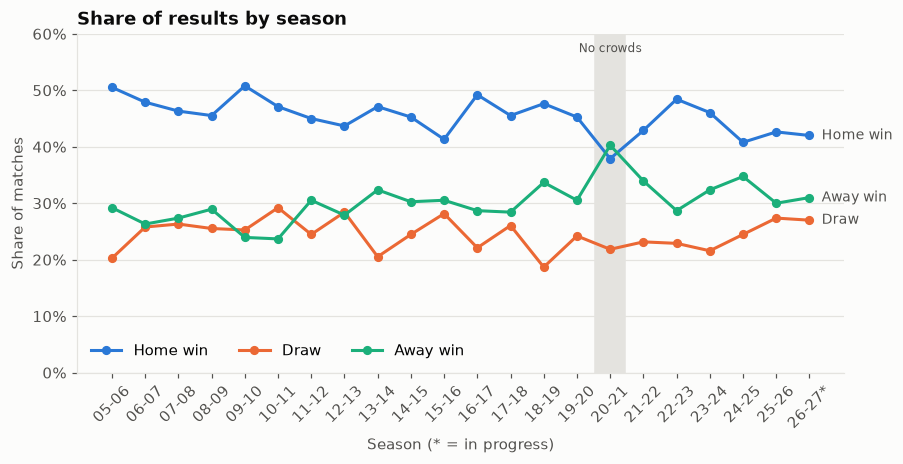

In [5]:
overall = df["result"].value_counts(normalize=True)[OUTCOMES]
print("Overall:", ", ".join(f"{OUTCOME_LABELS[o]} {overall[o]:.1%}" for o in OUTCOMES))

shares = pd.crosstab(df["season"], df["result"], normalize="index").loc[SEASONS, OUTCOMES]

fig, ax = plt.subplots()
ax.set_ylim(0, 0.6)
x = season_axis(ax)
for o in OUTCOMES:
    ax.plot(x, shares[o], marker="o", color=OUTCOME_COLORS[o], label=OUTCOME_LABELS[o])
    ax.annotate(OUTCOME_LABELS[o], (x[-1], shares[o].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9, color=TEXT_MUTED)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("Share of matches")
ax.set_title("Share of results by season")
ax.legend(loc="lower left", ncol=3)
plt.show()

**Notes:** overall home/draw/away split? How much does it move between seasons? What happened in 2020-21?
 about a 9:4:6 split, small variations between seasons, covide happened and home advantage was taken away.

## 3. Goals and home advantage

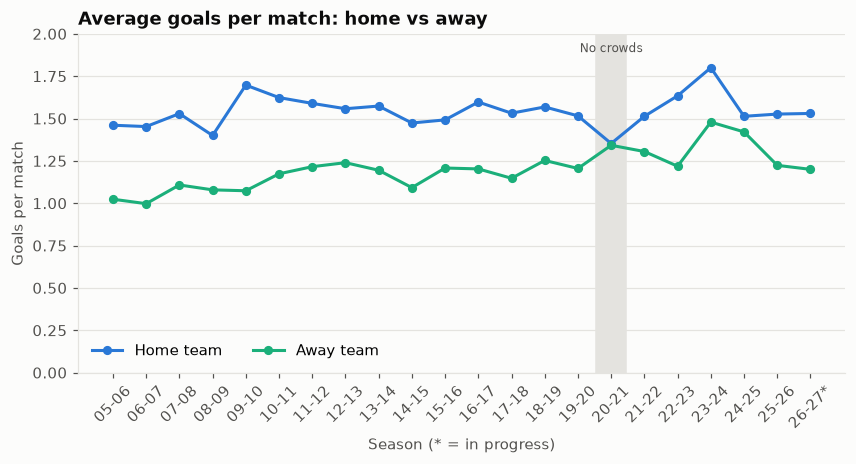

season,2005-06,2006-07,2007-08,2008-09,2009-10,2010-11,2011-12,2012-13,2013-14,2014-15,...,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26,2026-27
home_goals,1.46,1.45,1.53,1.40,1.70,1.62,1.59,1.56,1.57,1.47,...,1.53,1.57,1.52,1.35,1.51,1.63,1.80,1.51,1.53,1.53
away_goals,1.02,1.00,1.11,1.08,1.07,1.17,1.22,1.24,1.19,1.09,...,1.15,1.25,1.21,1.34,1.31,1.22,1.48,1.42,1.22,1.20
home_edge,0.44,0.46,0.42,0.32,0.62,0.45,0.37,0.32,0.38,0.38,...,0.38,0.32,0.31,0.01,0.21,0.42,0.32,0.09,0.30,0.33


In [6]:
goals = df.groupby("season")[["home_goals", "away_goals"]].mean().loc[SEASONS]

fig, ax = plt.subplots()
ax.set_ylim(0, 2.0)
x = season_axis(ax)
for col, label, color in [("home_goals", "Home team", OUTCOME_COLORS["H"]),
                          ("away_goals", "Away team", OUTCOME_COLORS["A"])]:
    ax.plot(x, goals[col], marker="o", color=color, label=label)
ax.set_ylabel("Goals per match")
ax.set_title("Average goals per match: home vs away")
ax.legend(loc="lower left", ncol=2)
plt.show()

goals.assign(home_edge=goals["home_goals"] - goals["away_goals"]).round(2).T

**Notes:** how many extra goals does playing at home give, on average? Is home advantage constant over time?
half a goal advantage. is has decreased over the years with 20/21 being an anomoly.

## 4. The bookmakers' margin

Bookmaker odds include a profit margin: 1/odds summed over the three outcomes is a bit more than 100%. `implied_probabilities` removes it so the probabilities sum to 1.

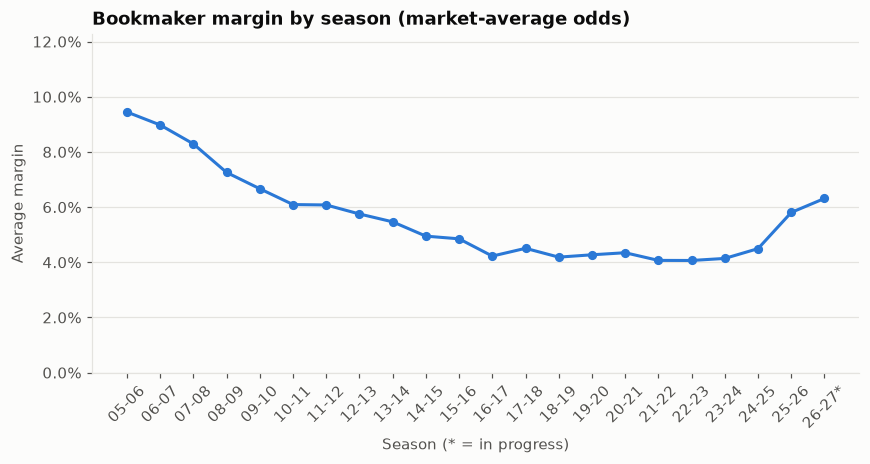

In [7]:
margin = df.groupby("season")["margin"].mean().loc[SEASONS]

fig, ax = plt.subplots()
ax.set_ylim(0, margin.max() * 1.3)
x = season_axis(ax, mark_covid=False)
ax.plot(x, margin, marker="o", color=SINGLE)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.set_ylabel("Average margin")
ax.set_title("Bookmaker margin by season (market-average odds)")
plt.show()

## 5. How good are the bookmakers?

**Calibration:** when the bookmakers say an outcome is 60% likely, does it happen about 60% of the time? Group matches by predicted probability, then compare with how often the outcome actually happened. Points on the dashed diagonal = perfectly calibrated.

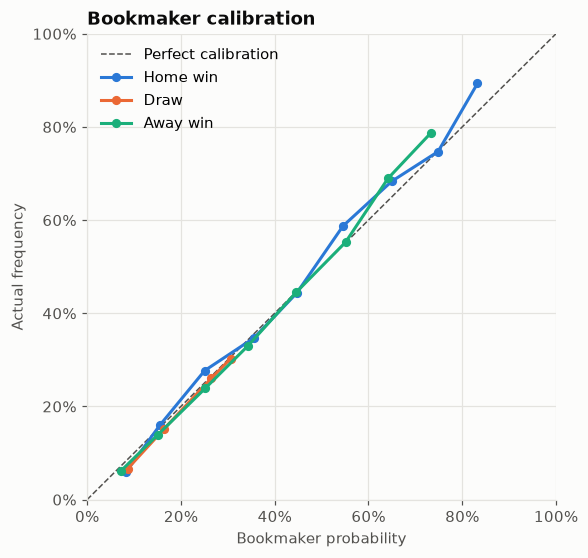

In [8]:
bins = np.linspace(0, 1, 11)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], ls="--", lw=1, color=TEXT_MUTED, label="Perfect calibration")
for o, col in zip(OUTCOMES, ["p_home", "p_draw", "p_away"]):
    actual = (df["result"] == o).astype(float)
    groups = pd.DataFrame({"pred": df[col], "actual": actual}).groupby(pd.cut(df[col], bins), observed=True)
    table = groups.agg(pred=("pred", "mean"), actual=("actual", "mean"), n=("actual", "size"))
    table = table[table["n"] >= 30]  # too few matches in a bin = too noisy to judge
    ax.plot(table["pred"], table["actual"], marker="o", color=OUTCOME_COLORS[o], label=OUTCOME_LABELS[o])
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Bookmaker probability", ylabel="Actual frequency")
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_title("Bookmaker calibration")
ax.legend(loc="upper left")
plt.show()

In [9]:
# How often does the bookmakers' favourite win? And how often is a draw the favourite?
probs = df[["p_home", "p_draw", "p_away"]].to_numpy()
favourite = np.array(OUTCOMES)[probs.argmax(axis=1)]
print(f"Favourite wins:            {(favourite == df['result']).mean():.1%}")
print(f"Draw is the favourite in:  {(favourite == 'D').mean():.1%} of matches")
print(f"Draw probability range:    {df['p_draw'].min():.0%} to {df['p_draw'].max():.0%}")

Favourite wins:            54.6%
Draw is the favourite in:  0.0% of matches
Draw probability range:    7% to 33%


**Notes:** are the bookmakers well calibrated? How often does the favourite win? Why are draws so hard to predict?
bookmakers are really well calibrated. the favourite wins 54.6% of time. draws are never the favorite outcome and it seems to have a descent probability range.

## 6. Summary: what this means for modelling

Write 3–4 bullets, for example:
- the base rates a simple model should start from;
- whether home advantage can be treated as fixed;
- how strong the bookmaker benchmark is;
- anything surprising.